*FCEIA - Tec. Universitaria en Inteligencia Artificial - Minería de Datos*

---
# Árboles de decisión: Regresión




# 🎯 Objetivo
Explorar algunas funcionalidades del algoritmo aplicándolas a la base de datos de *Taxi Fares*.

# ⚙️ Configuración

In [9]:

# Análisis exploratorio
import gdown
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# Árboles de desición
from sklearn.tree import (DecisionTreeRegressor, plot_tree, export_graphviz,
                          export_text)
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from graphviz import Source

# Métricas
from sklearn.metrics import (confusion_matrix, mean_absolute_error,
                             mean_squared_error)


from sklearn.pipeline import make_pipeline
import itertools

# 📂 Base de datos: *Taxi Fares*

Este dataset contiene varios archivos de datos con el fin de predecir la tarifa de taxi en Nueva York.

Los datos fueron recolectados a lo largo de varios años e incluyen información sobre viajes en taxi y autos alquilados en la ciudad de Nueva York. El conjunto de datos se ha puesto a disposición del público en el [sitio web de New York City Taxi and Limousine Commission (TLC)](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).

Fuente de datos: https://www.kaggle.com/datasets/venessagreen/predicting-taxi-fares-by-utilizing-random-forests

Para este caso práctico, solo utilizaremos el archivo `taxi.csv` y `trip.csv`.

Las variables que contiene *taxi.csv* son:
- medaillion : id único de viaje.
- pickup_datetime: fecha, hora, min y segundo en la que el taxi subió al pasajero. En formato YYYY-mm-dd hh:mm:ss.
- pickup_longitude: coordenada longitud de punto de partida.
- pickup_latitude: coordenada latitud de punto de partida.
- trip_time_in_secs: tiempo de viaje en segundos.
- fare_amount: tarifa del viaje.
- tip_amount: propina del viaje.

Las variables que utilizaremos de *trip.csv* son:
- passangers: cantidad de pasajeros.
- trip_distance: distancia del viaje en km.
- dropoff_longitude: coordenada longitud de punto de partida.
- dropoff_latitude: coordenada latitud de punto de partida.

In [10]:
# ID del archivo
file_id = "18MI932ho-E_0tKb093LV-x6Ver9Vy_fV"
# URL directa para gdown
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar
output = "taxi.csv"
gdown.download(url, output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=18MI932ho-E_0tKb093LV-x6Ver9Vy_fV
To: /content/taxi.csv
100%|██████████| 4.25M/4.25M [00:00<00:00, 201MB/s]


'taxi.csv'

In [11]:
# ID del archivo
file_id = "1kr4T4VRYk7EPRIz3wOAqiIWCJL5x9U0X"
# URL directa para gdown
url = f"https://drive.google.com/uc?id={file_id}"

# Descargar
output = "trip.csv"
gdown.download(url, output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1kr4T4VRYk7EPRIz3wOAqiIWCJL5x9U0X
To: /content/trip.csv
100%|██████████| 8.41M/8.41M [00:00<00:00, 32.2MB/s]


'trip.csv'

# 📊 Estructura
Nombre de variables, variable objetivo, tipos de datos y valores nulos.

In [12]:
taxi = pd.read_csv("taxi.csv")
taxi.head()

,medallion,pickup_datetime,pickup_longitude,pickup_latitude,trip_time_in_secs,fare_amount,tip_amount
0,4D24F4D8EF35878595044A52B098DFD2,2013-01-13T10:23:00Z,-73.946457,40.772728,600,8.0,2.5
1,A49C37EB966E7B05E69523D1CB7BE303,2013-01-13T04:52:00Z,-73.998268,40.740414,840,18.0,0.0
2,1E4B72A8E623888F53A9693C364AC05A,2013-01-13T10:47:00Z,-73.953461,40.775864,60,3.5,0.7
3,F7E4E9439C46B8AD5B16AB9F1B3279D7,2013-01-13T11:14:00Z,-73.981369,40.724731,720,11.5,2.3
4,A9DC75D59E0EA27E1ED328E8BE8CD828,2013-01-13T11:24:00Z,-73.967995,40.760002,240,6.5,0.0


In [13]:
taxi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   medallion          49999 non-null  object 
 1   pickup_datetime    49999 non-null  object 
 2   pickup_longitude   49999 non-null  float64
 3   pickup_latitude    49999 non-null  float64
 4   trip_time_in_secs  49999 non-null  int64  
 5   fare_amount        49999 non-null  float64
 6   tip_amount         49999 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 2.7+ MB


In [14]:
trip = pd.read_csv('trip.csv')
trip.head()

,medallion,hack_license,vendor_id,rate_code,store_and_fwd_flag,pickup_datetime,dropoff_datetime,passenger_count,trip_time_in_secs,trip_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
0,4D24F4D8EF35878595044A52B098DFD2,EEF7A2EC022DA207C643827D661999EC,VTS,1,NaN,2013-01-13T10:23:00Z,2013-01-13T10:33:00Z,1,600,1.11,-73.946457,40.772728,-73.954819,40.777840
1,A49C37EB966E7B05E69523D1CB7BE303,CA63EB3459FD5D97D4434EAFDE224898,VTS,1,NaN,2013-01-13T04:52:00Z,2013-01-13T05:06:00Z,1,840,5.35,-73.998268,40.740414,-73.984909,40.674999
2,1E4B72A8E623888F53A9693C364AC05A,06545280CEF9EE7070FD95246E6479C8,VTS,1,NaN,2013-01-13T10:47:00Z,2013-01-13T10:48:00Z,5,60,0.50,-73.953461,40.775864,-73.955238,40.773216
3,F7E4E9439C46B8AD5B16AB9F1B3279D7,08E1CEA4851C1A6BC150CD26D6D42C00,VTS,1,NaN,2013-01-13T11:14:00Z,2013-01-13T11:26:00Z,1,720,2.66,-73.981369,40.724731,-74.012932,40.717426
4,A9DC75D59E0EA27E1ED328E8BE8CD828,94E1D7C28F66ED93BD4A90B74FAB7356,VTS,1,NaN,2013-01-13T11:24:00Z,2013-01-13T11:28:00Z,6,240,1.49,-73.967995,40.760002,-73.955513,40.776730


In [15]:
trip.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   medallion           49999 non-null  object 
 1   hack_license        49999 non-null  object 
 2   vendor_id           49999 non-null  object 
 3   rate_code           49999 non-null  int64  
 4   store_and_fwd_flag  25319 non-null  object 
 5   pickup_datetime     49999 non-null  object 
 6   dropoff_datetime    49999 non-null  object 
 7   passenger_count     49999 non-null  int64  
 8   trip_time_in_secs   49999 non-null  int64  
 9   trip_distance       49999 non-null  float64
 10  pickup_longitude    49999 non-null  float64
 11  pickup_latitude     49999 non-null  float64
 12  dropoff_longitude   49999 non-null  float64
 13  dropoff_latitude    49999 non-null  float64
dtypes: float64(5), int64(3), object(6)
memory usage: 5.3+ MB


In [16]:
trip = trip[['passenger_count', 'trip_distance','dropoff_longitude','dropoff_latitude']]

## Concatenar df por id de viaje

In [17]:
data = pd.concat([taxi, trip], axis = 1)
data.head()

,medallion,pickup_datetime,pickup_longitude,pickup_latitude,trip_time_in_secs,fare_amount,tip_amount,passenger_count,trip_distance,dropoff_longitude,dropoff_latitude
0,4D24F4D8EF35878595044A52B098DFD2,2013-01-13T10:23:00Z,-73.946457,40.772728,600,8.0,2.5,1,1.11,-73.954819,40.777840
1,A49C37EB966E7B05E69523D1CB7BE303,2013-01-13T04:52:00Z,-73.998268,40.740414,840,18.0,0.0,1,5.35,-73.984909,40.674999
2,1E4B72A8E623888F53A9693C364AC05A,2013-01-13T10:47:00Z,-73.953461,40.775864,60,3.5,0.7,5,0.50,-73.955238,40.773216
3,F7E4E9439C46B8AD5B16AB9F1B3279D7,2013-01-13T11:14:00Z,-73.981369,40.724731,720,11.5,2.3,1,2.66,-74.012932,40.717426
4,A9DC75D59E0EA27E1ED328E8BE8CD828,2013-01-13T11:24:00Z,-73.967995,40.760002,240,6.5,0.0,6,1.49,-73.955513,40.776730


In [18]:
print(f'taxi tiene {len(taxi)} muestras')
print(f'trip tiene {len(trip)} muestras\n')
data.info()

taxi tiene 49999 muestras
trip tiene 49999 muestras

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   medallion          49999 non-null  object 
 1   pickup_datetime    49999 non-null  object 
 2   pickup_longitude   49999 non-null  float64
 3   pickup_latitude    49999 non-null  float64
 4   trip_time_in_secs  49999 non-null  int64  
 5   fare_amount        49999 non-null  float64
 6   tip_amount         49999 non-null  float64
 7   passenger_count    49999 non-null  int64  
 8   trip_distance      49999 non-null  float64
 9   dropoff_longitude  49999 non-null  float64
 10  dropoff_latitude   49999 non-null  float64
dtypes: float64(7), int64(2), object(2)
memory usage: 4.2+ MB


In [19]:
data.drop(columns=['medallion', 'pickup_datetime'], inplace=True)

## Distribuciones

In [20]:
data.describe()

,pickup_longitude,pickup_latitude,trip_time_in_secs,fare_amount,tip_amount,passenger_count,trip_distance,dropoff_longitude,dropoff_latitude
count,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000,49999.000000
mean,-72.562461,39.825872,757.281306,12.443674,1.376561,1.693414,2.907660,-72.539657,39.812613
std,10.773865,7.837667,654.997964,13.658216,2.132299,1.361815,3.377631,10.846693,7.872047
min,-82.634415,-74.014969,0.000000,0.000000,0.000000,0.000000,0.000000,-77.115440,-74.177155
25%,-73.992294,40.734245,365.000000,6.500000,0.000000,1.000000,1.060000,-73.991592,40.733475
50%,-73.982025,40.752079,600.000000,9.500000,1.000000,1.000000,1.800000,-73.980255,40.752808
75%,-73.966904,40.767099,960.000000,14.000000,2.000000,2.000000,3.200000,-73.963593,40.767857
max,40.811337,41.589775,75240.000000,2069.500000,62.000000,6.000000,53.000000,40.859077,41.107189


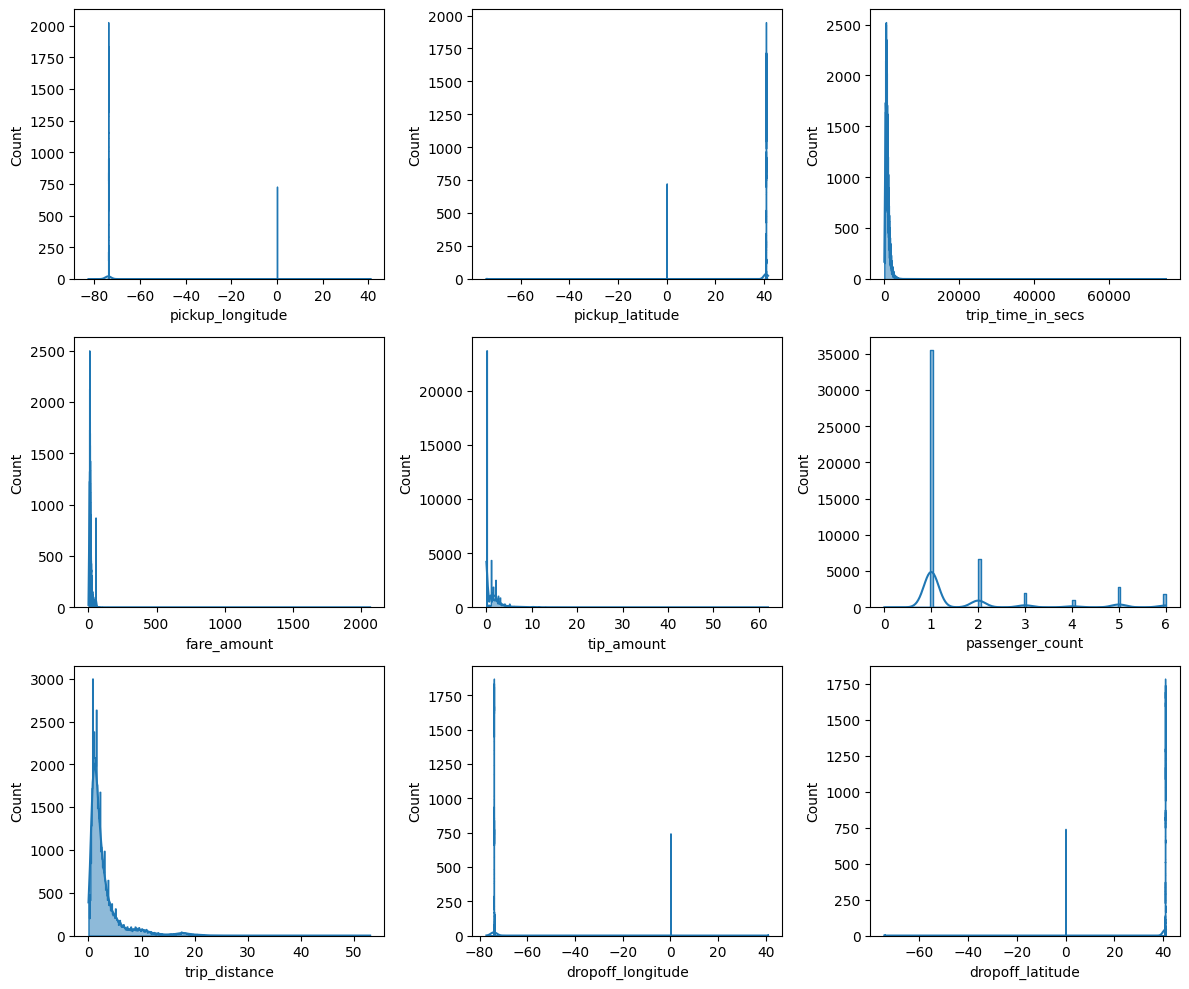

In [21]:
cols = data.select_dtypes(include=np.number).columns
fig, axes = plt.subplots(nrows=3, ncols=3, sharey=False,
                         figsize=(12, 10))
for i, col in enumerate(cols, 1):
    sns.histplot(data=data, x=col, kde=True, element='step',
                 ax=axes.flatten()[i-1])

plt.tight_layout()
plt.show()

# ❌ Descarte de variables.

*Data Leakage | Fuga de Datos*

En simples palabras, es cuando un modelo utiliza información durante su entrenamiento que no estaría disponible al hacer predicciones en el mundo real.

Caso más común:
- Introducir la variable a predecir.
- Introducir una variable que sólo puedo saber luego del que fenómeno a predecir haya ocurrido.

❓ **¿Qué variables les parece que estaría mal introducir al modelo?**

In [22]:
data.columns

Index(['pickup_longitude', 'pickup_latitude', 'trip_time_in_secs',
       'fare_amount', 'tip_amount', 'passenger_count', 'trip_distance',
       'dropoff_longitude', 'dropoff_latitude'],
      dtype='object')

Pensemos... ¿qué variable sólo puedo conocer una vez que el viaje haya terminado?

- coordenada latitud de inicio
- coordenada longitud de inicio
- tiempo de viaje
- ~tarifa~
- propina
- cantidad de pasajeros
- distancia de viaje
- coordenada latitud de fin
- coordenada longitud de fin

## Posible respuesta

- propina: el pasajero da la propina al finalizar el viaje.
- tiempo de viaje: si bien sí existe un *tiempo de viaje estimado* en la actualidad, el tiempo de viaje propiamente dicho sólo se conoce al terminar el mismo.

In [23]:
data = data.drop(columns = ['tip_amount', 'trip_time_in_secs'])

In [24]:
data.columns

Index(['pickup_longitude', 'pickup_latitude', 'fare_amount', 'passenger_count',
       'trip_distance', 'dropoff_longitude', 'dropoff_latitude'],
      dtype='object')

# ✅ Conjunto de prueba

In [25]:
# Separo variable objetivo de datos
X = data.drop('fare_amount', axis=1)
y = data['fare_amount']

In [26]:
# Obtengo datos de entrenamiento y de testeo
X_train, X_test, y_train, y_test  = train_test_split(X, y, test_size=0.2,
                            random_state=13, shuffle=True)

In [27]:
# Obtengo datos de entrenamiento y de validacion
X_test, X_val, y_test, y_val  = train_test_split(X_test, y_test, test_size=0.2,
                            random_state=11, shuffle=True)

# 🔎 Análisis exploratorio

## Correlación entre variables

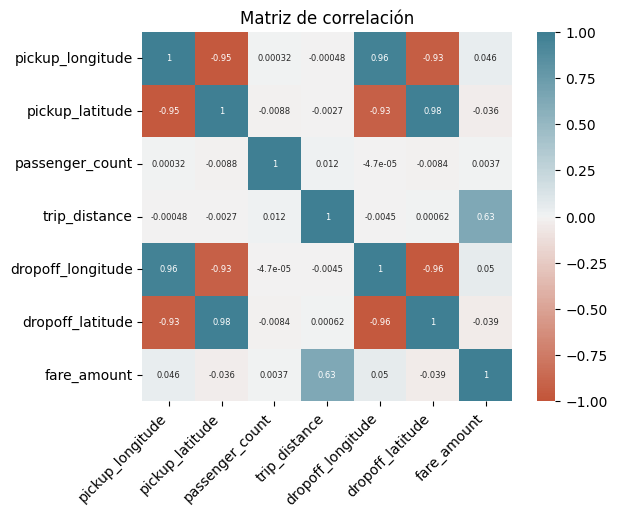

In [28]:
num_cols = X_train.select_dtypes(include=np.number).columns
corr = pd.concat([X_train[num_cols], y_train], axis=1).corr()
ax = sns.heatmap(
    corr,
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True,
    annot = True,
    annot_kws = {'size': 6}
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
)
plt.title('Matriz de correlación')
plt.show()

## Boxplot

<Axes: >

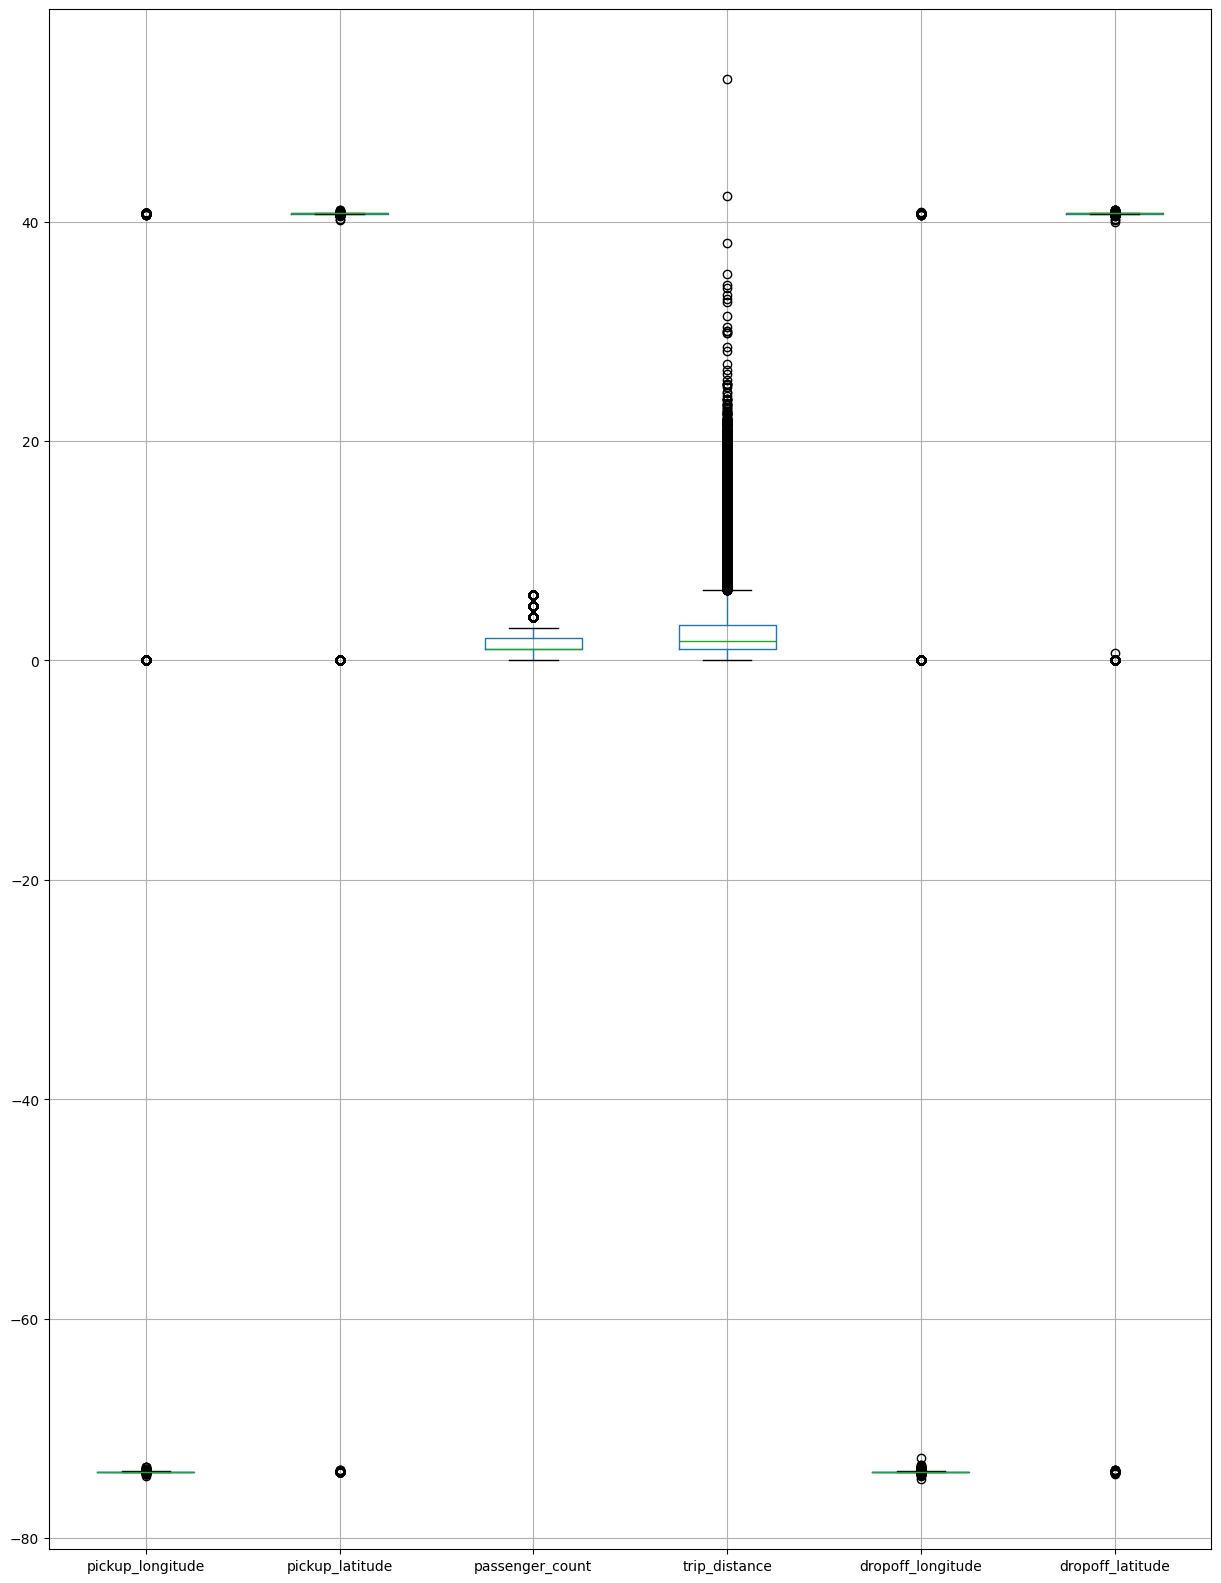

In [29]:
X_train[num_cols].boxplot(figsize=(15,20))

# 🔧 Preparación de los datos

## 🧹 Limpieza

### Valores atípicos

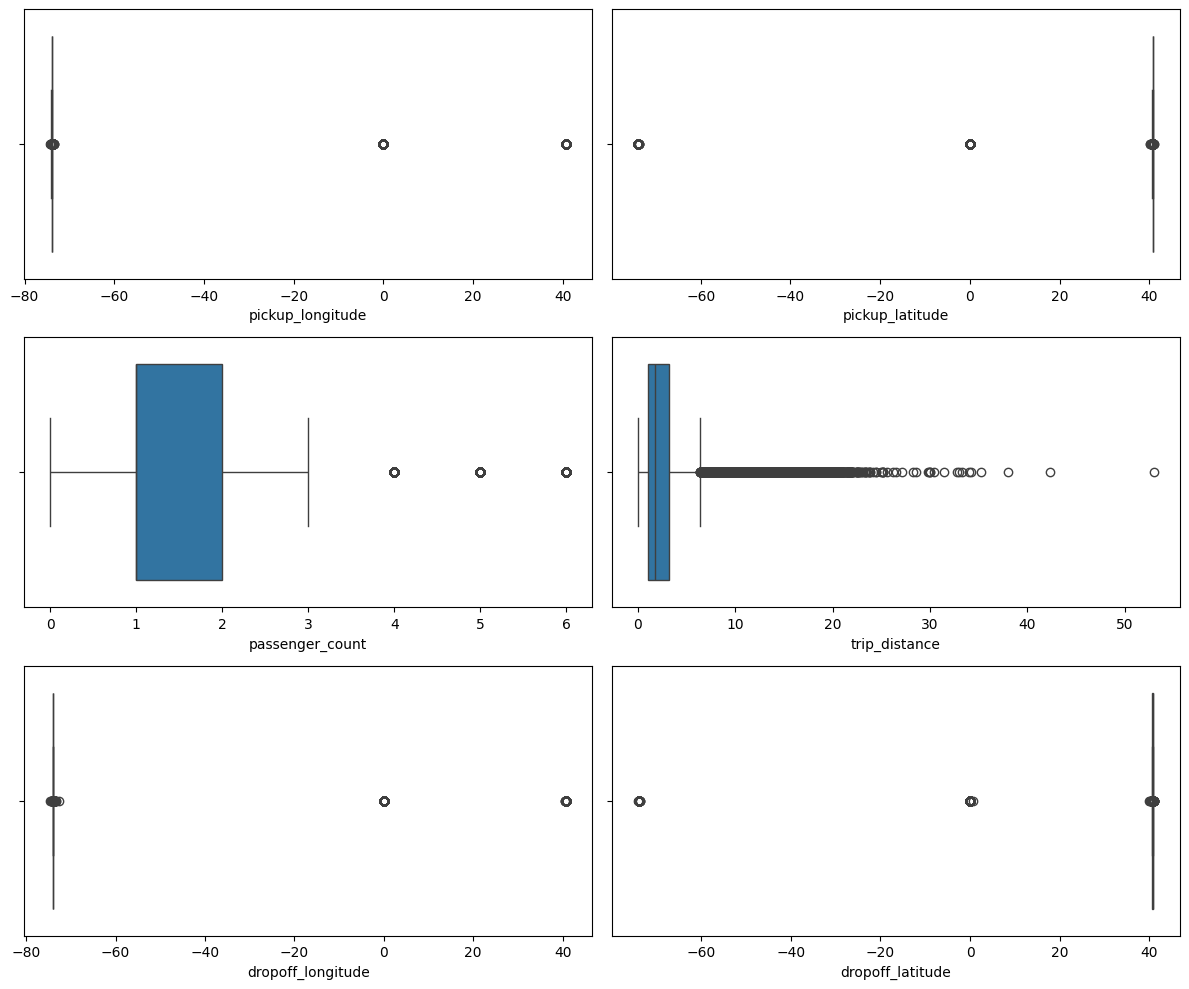

In [30]:
fig, axes = plt.subplots(nrows=3, ncols=2, sharey=False,
                         figsize=(12, 10))
for i, col in enumerate(num_cols, 1):
    sns.boxplot(data=X_train, x=col, ax=axes.flatten()[i-1])

plt.tight_layout()
plt.show()

In [31]:
## Conteo de atípicos por columna
results = []
for col in X_train[num_cols]:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    num_outliers = len(outliers)
    percentage = (num_outliers / len(data)) * 100
    results.append({'Variable': col, 'Cantidad': num_outliers, 'Porcentaje': percentage})

# Crear DataFrame a partir de los resultados
df_outliers = pd.DataFrame(results)

# Formatear la columna de porcentaje
df_outliers['Porcentaje'] = df_outliers['Porcentaje'].map('{:.1f}%'.format)

print('Valores atípicos:')
print(df_outliers.to_markdown(numalign="left", stralign="left",
                              tablefmt="simple", index = False))


Valores atípicos:
Variable           Cantidad    Porcentaje
-----------------  ----------  ------------
pickup_longitude   3400        6.8%
pickup_latitude    2273        4.5%
passenger_count    5758        11.5%
trip_distance      4859        9.7%
dropoff_longitude  3340        6.7%
dropoff_latitude   2962        5.9%


Usando el conocimiento para limpiar atípicos.

1. coordenadas: sabemos que Nueva York (ciudad) se encuentra dentro de estos rangos de coordenadas:
  - longitud: desde -74.25° y -73.7°
  - latitud: 40.5° y 40.9°

In [32]:
# Filas donde longitud se vaya del rango -74.25° y -73.7°
PLon = (X_train['pickup_longitude'] >= -74.25) & (X_train['pickup_longitude'] <= -73.7)
DLon = (X_train['dropoff_longitude'] >= -74.25) & (X_train['dropoff_longitude'] <= -73.7)
outliers = PLon & DLon

In [33]:
len(X_train[outliers])

39245

In [34]:
# Filas donde latitud se vaya del rango 40.5° - 40.9°
PLat = (X_train['pickup_latitude'] >= 40.5) & (X_train['pickup_latitude'] <= 40.9)
DLat = (X_train['dropoff_latitude'] >= 40.5) & (X_train['dropoff_latitude'] <= 40.9)
outliers = outliers & PLat & DLat

In [35]:
len(X_train[outliers])

39226

2. Distancia de viaje.
La distancia máxima de un viaje dentro de la ciudad de nueva york es algo difícil de saber.

El viaje más largo, solo de ida, se da entre Pearth Amboy y Mt Vernon. Es decir, 56 km aproximadamente si calculamos la distancia euclídeana. Por lo que los valores en los que se encuentra trip_distance son valores que pueden suceder (el valor máximo es 53 km)

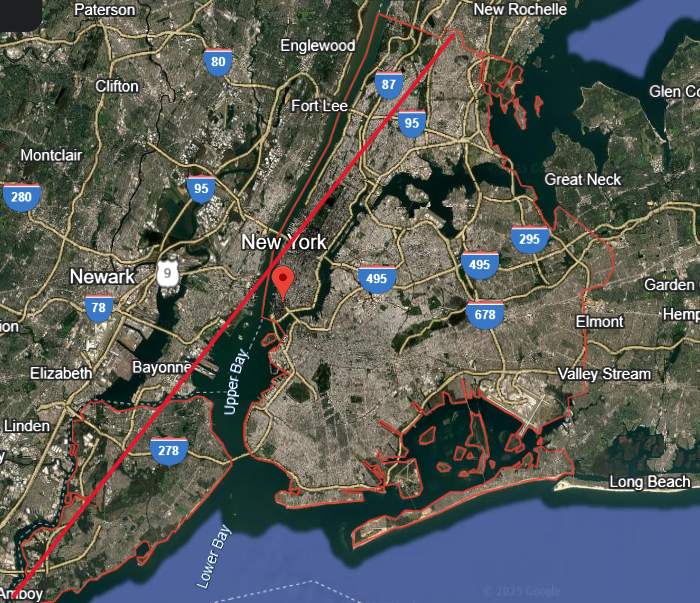

3. Cantidad de pasajeros.
En un taxi no pueden, físicamente ni legalmente, entrar más de 4 pasajeros.

In [36]:
PC = X_train['passenger_count']<= 4
outliers = outliers & PC

In [37]:
len(X_train[outliers])

35534

4. Tarifa.

Primero, sabemos que una tarifa no puede ser menor o igual a 0.

In [38]:
FA = y_train > 0
outliers = outliers & FA

In [39]:
len(X_train[outliers])

35533

El máximo de una tarifa en nuestros datos, tras la limpieza es USD 119.5:

In [40]:
y_train[outliers].max()

119.5

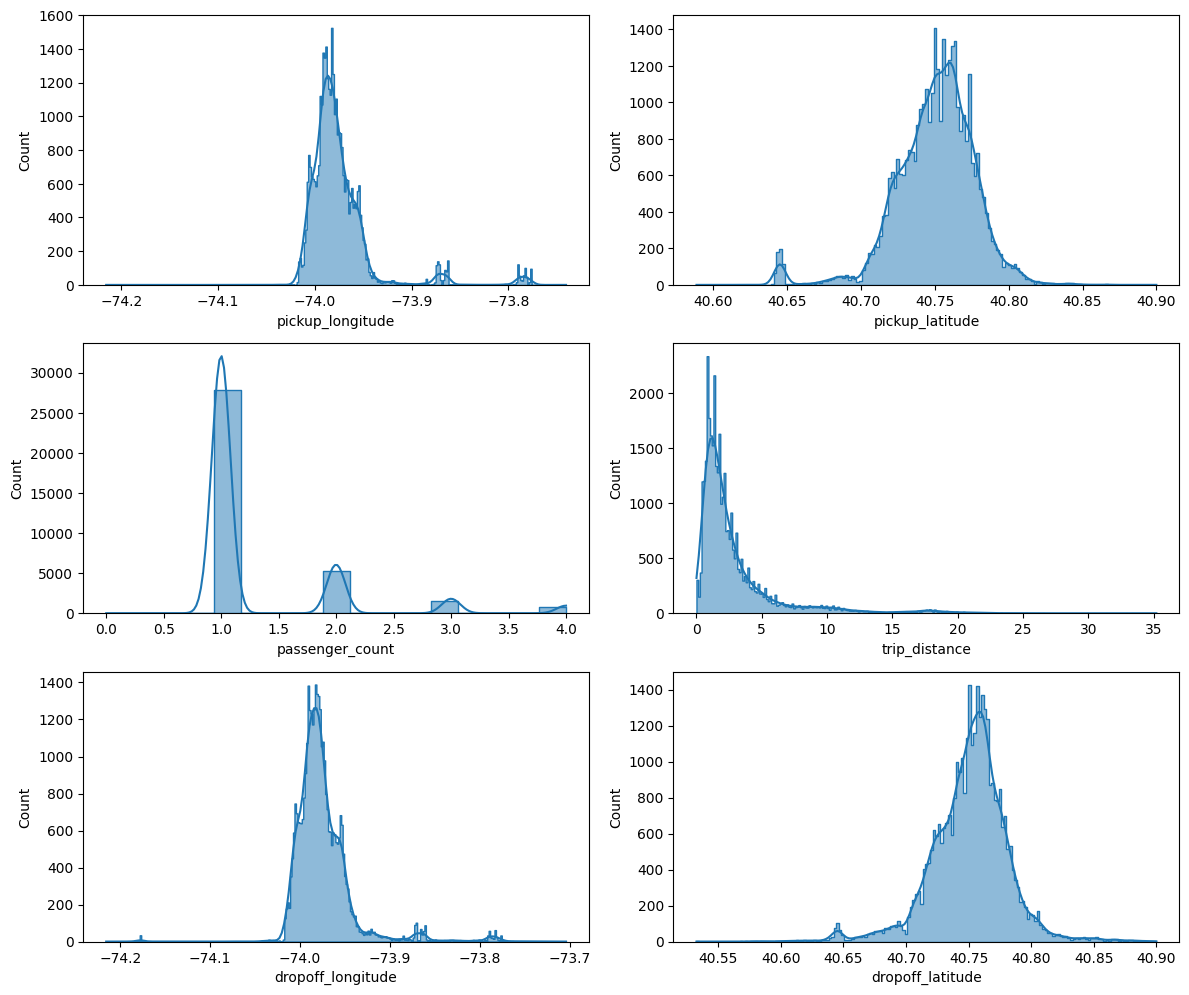

In [41]:
fig, axes = plt.subplots(nrows=3, ncols=2, sharey=False,
                         figsize=(12, 10))
for i, col in enumerate(num_cols, 1):
    sns.histplot(data=X_train[outliers], x=col, kde=True, element='step',
                 ax=axes.flatten()[i-1])

plt.tight_layout()
plt.show()

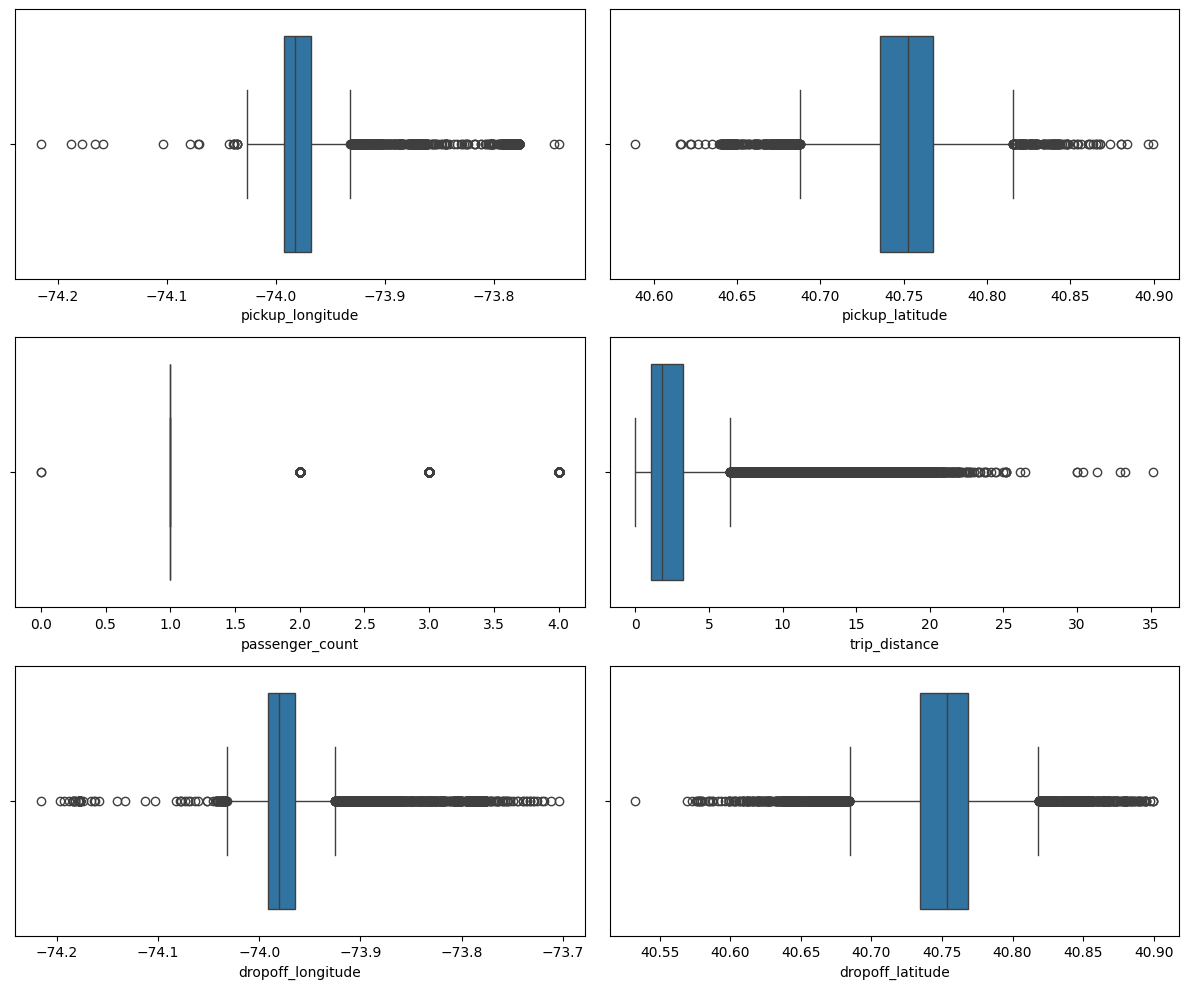

In [42]:
fig, axes = plt.subplots(nrows=3, ncols=2, sharey=False,
                         figsize=(12, 10))
for i, col in enumerate(num_cols, 1):
    sns.boxplot(data=X_train[outliers], x=col, ax=axes.flatten()[i-1])

plt.tight_layout()
plt.show()

#🌳📈 Regresion tree

In [43]:
# Selección del modelo: hiperparámetros
tree_reg = DecisionTreeRegressor(max_depth=None, criterion='squared_error',
                                 min_samples_leaf=1, min_samples_split=2,
                                 random_state=13)
# Entrenamiento
tree_reg.fit(X_train[outliers], y_train[outliers])

DecisionTreeRegressor(random_state=13)

## Visualización

In [44]:
# Lista de nombres de las variables
vars_names = list(X_train.columns)
print(vars_names)

['pickup_longitude', 'pickup_latitude', 'passenger_count', 'trip_distance', 'dropoff_longitude', 'dropoff_latitude']


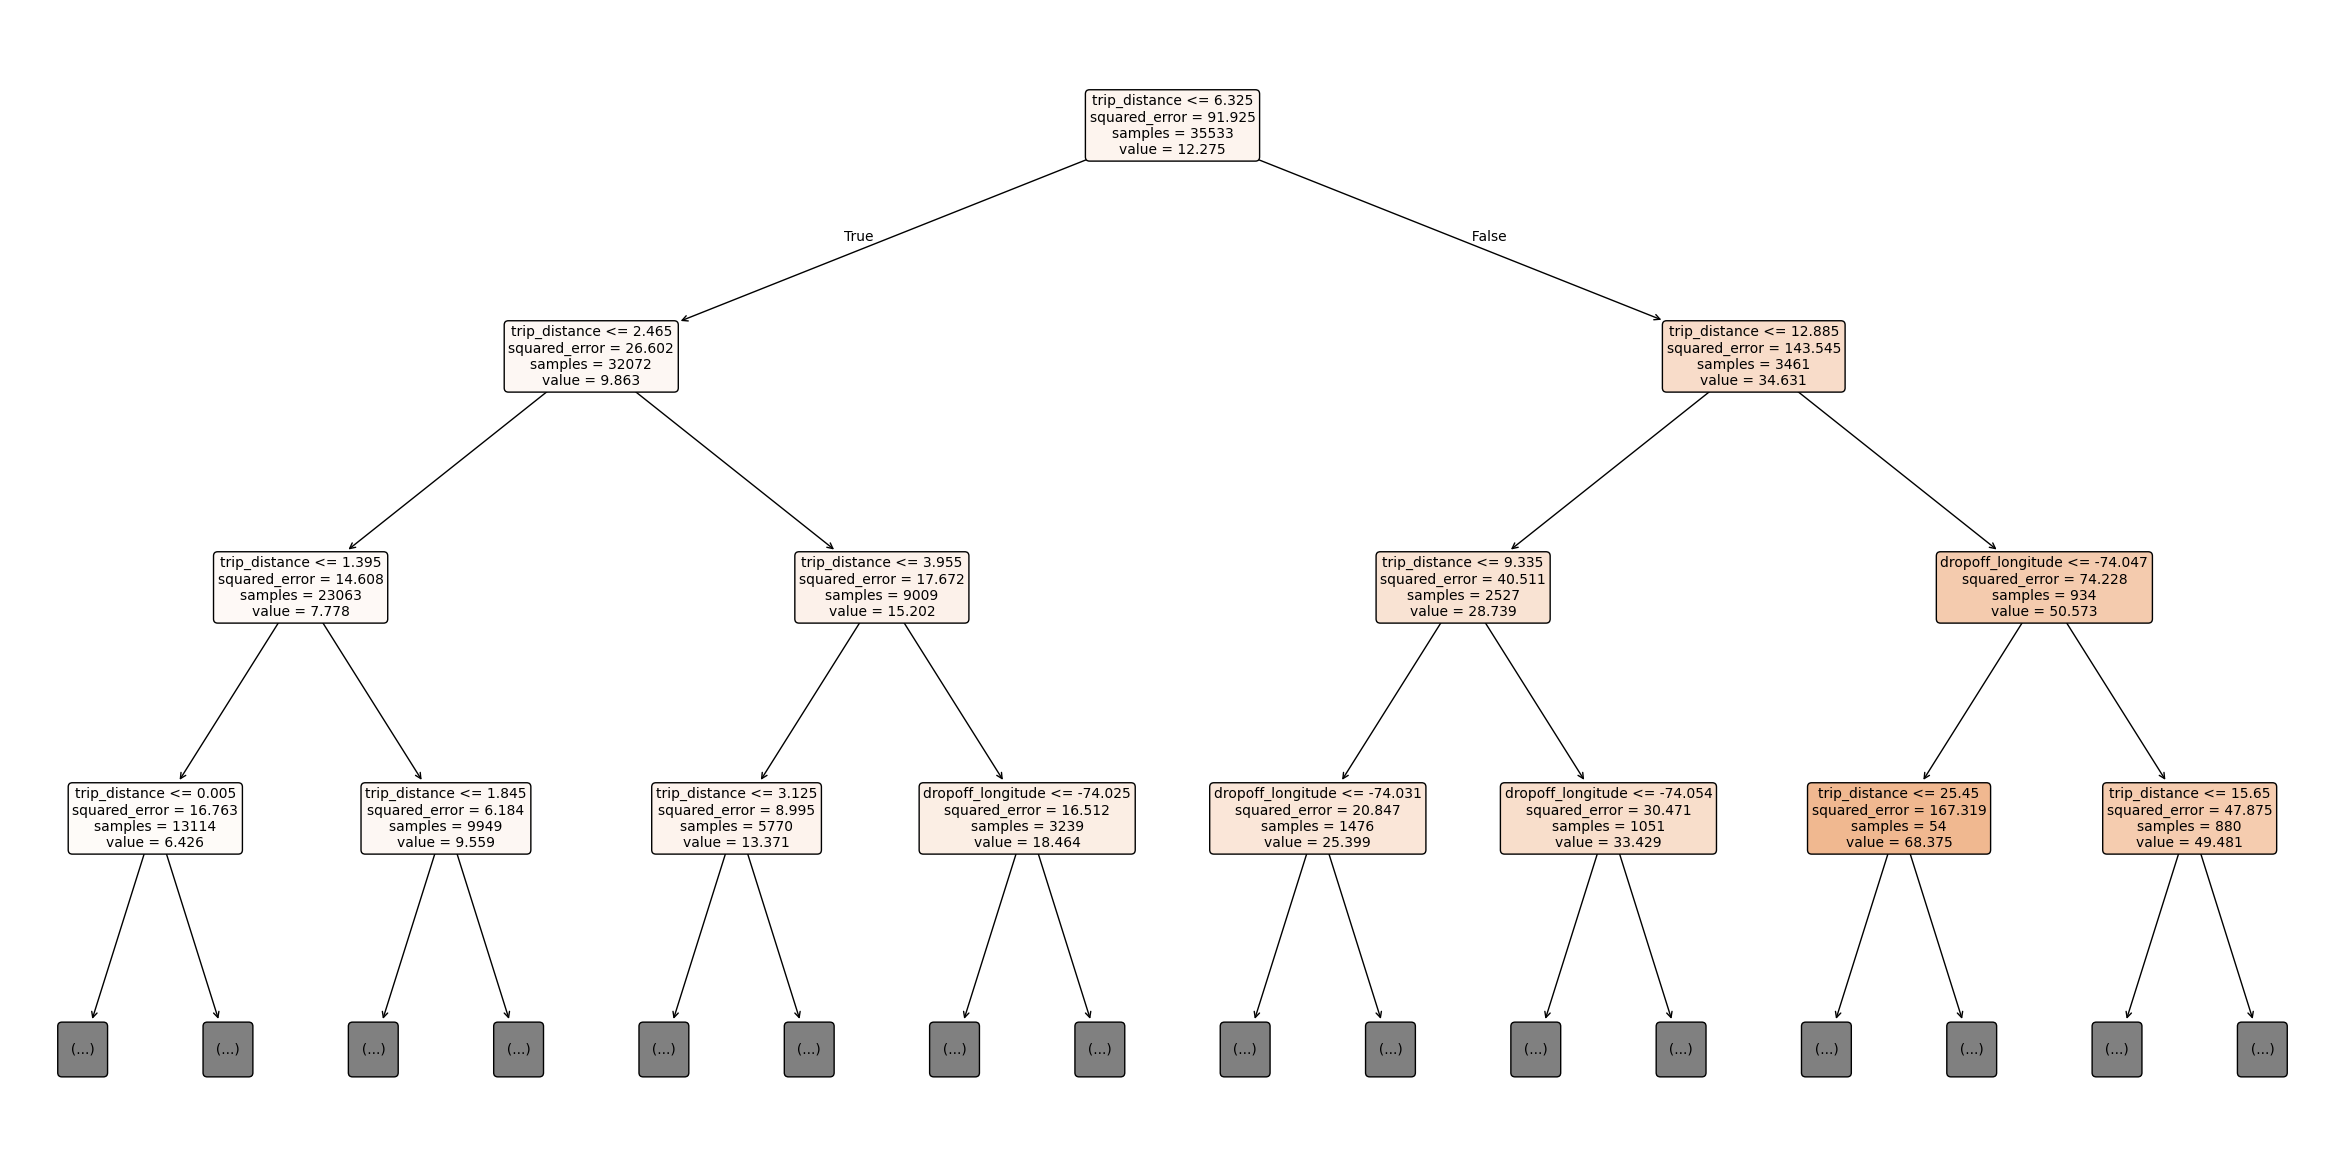

In [45]:
plt.figure(figsize=(30, 15))
plot_tree(tree_reg, feature_names=vars_names, fontsize=10, filled=True,
          rounded=True, max_depth=3)
plt.show()


In [46]:
tree_rules = export_text(tree_reg, feature_names=vars_names, max_depth=5)
print(tree_rules)

|--- trip_distance <= 6.33
|   |--- trip_distance <= 2.47
|   |   |--- trip_distance <= 1.39
|   |   |   |--- trip_distance <= 0.00
|   |   |   |   |--- pickup_longitude <= -73.81
|   |   |   |   |   |--- dropoff_longitude <= -74.03
|   |   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |   |--- dropoff_longitude >  -74.03
|   |   |   |   |   |   |--- truncated branch of depth 22
|   |   |   |   |--- pickup_longitude >  -73.81
|   |   |   |   |   |--- pickup_longitude <= -73.79
|   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |   |--- pickup_longitude >  -73.79
|   |   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- trip_distance >  0.00
|   |   |   |   |--- trip_distance <= 0.88
|   |   |   |   |   |--- pickup_longitude <= -74.03
|   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |   |--- pickup_longitude >  -74.03
|   |   |   |   |   |   |--- truncated branch of depth 43
|   |   |   |   |--- trip_distan

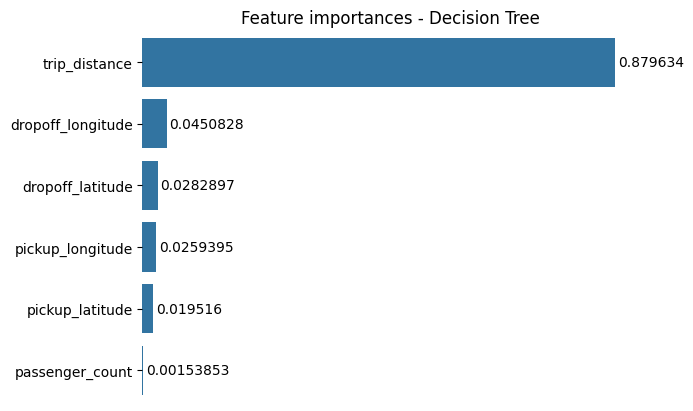

In [47]:
# Creo un df con dos columnas -> Caracteristica y ganacia de información
features_df = pd.DataFrame({'features': vars_names,
                            'importances': tree_reg.feature_importances_ })

# Ordeno en base a la importancia
features_df_sorted = features_df.sort_values(by='importances', ascending=False)

g = sns.barplot(data=features_df_sorted, x='importances', y ='features')
sns.despine(bottom = True, left = True)
g.set_title('Feature importances - Decision Tree')
g.set(xlabel=None, ylabel=None, xticks=[])
for value in g.containers:
    g.bar_label(value, padding=2)

In [48]:
# Predicción en el conjunto de entrenamiento
pred_trn = tree_reg.predict(X_train[outliers])

# Predicción en el conjunto de validación
pred_val = tree_reg.predict(X_val)

# Predicción en el conjunto de test
pred_test = tree_reg.predict(X_test)

## Métricas

- MSE (Error Medio Cuadrático): Es la media de los cuadrados de las diferencias entre los valores reales y los predichos. Penaliza fuertemente los errores grandes, por lo que un MSE bajo indica que las predicciones se ajustan bien a los datos, aunque sus unidades están al cuadrado de las originales.

- MAE (Error Absoluto Medio): Calcula la media de las diferencias absolutas entre los valores reales y los predichos. Es más interpretable que el MSE y menos sensible a valores atípicos, reflejando el error promedio en las mismas unidades de los datos.

- RMSE (Raíz del Error Medio Cuadrático): Es la raíz cuadrada del MSE, devolviendo el error en las mismas unidades que los datos. Combina la penalización de errores grandes del MSE con una interpretación más directa y fácil de comparar con los valores originales.

In [49]:
print('Error absoluto medio:', mean_absolute_error(y_val, pred_val))
print('Error medio cuadrado:', mean_squared_error(y_val, pred_val))
print('Raíz del error medio cuadrado:', np.sqrt(mean_squared_error(y_val,
                                                pred_val)))

Error absoluto medio: 2.3625
Error medio cuadrado: 30.14375
Raíz del error medio cuadrado: 5.490332412522943


In [50]:
tableResult = pd.DataFrame({'Real':y_val, 'Predicción':pred_val})
tableResult.head(10)

,Real,Predicción
3741,6.0,6.0
4657,9.5,15.5
4005,7.5,6.0
4934,11.5,12.5
39474,9.5,9.0
35470,4.5,10.0
25851,12.0,11.0
5,8.5,12.5
11074,7.0,8.0
29925,11.0,15.0


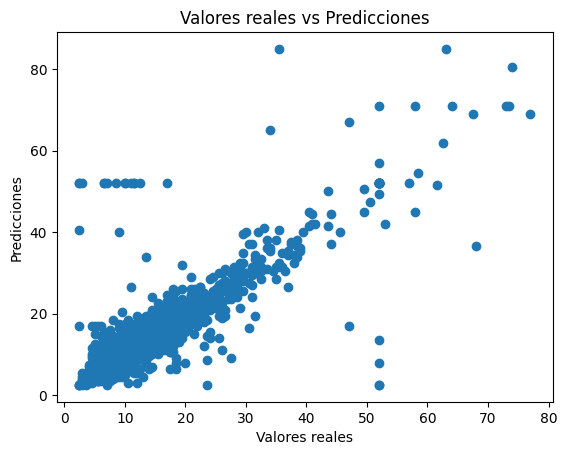

In [51]:
import matplotlib.pyplot as plt
# Graficar valores reales vs predicciones
plt.scatter(y_val, pred_val)
plt.xlabel("Valores reales")
plt.ylabel("Predicciones")
plt.title("Valores reales vs Predicciones")
plt.show()

## Optimización de hiperparámetros

In [52]:
param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 5, 10],
}

In [53]:
results_list = []

for max_depth, min_samples_split, min_samples_leaf in itertools.product(
    param_grid['max_depth'],
    param_grid['min_samples_split'],
    param_grid['min_samples_leaf']):
    # Crear un DecisionTreeRegressor base para pasar cada valor
    tree_reg = DecisionTreeRegressor(max_depth=max_depth,
                                     min_samples_split=min_samples_split,
                                     min_samples_leaf=min_samples_leaf,
                                     random_state=13)

    # Entrenar el modelo
    tree_reg.fit(X_train[outliers], y_train[outliers])
    #predecir
    pred_val = tree_reg.predict(X_val)

    # Calcular MSE
    mse = mean_squared_error(y_val, pred_val)

    # Agregar al dic de optimización los valores y la metrica
    results_list.append({
        'max_depth': max_depth,
        'min_samples_split': min_samples_split,
        'min_samples_leaf': min_samples_leaf,
        'MSE': mse
    })

In [54]:
df_results = pd.DataFrame(results_list)
df_results.head()

,max_depth,min_samples_split,min_samples_leaf,MSE
0,3.0,2,1,16.036719
1,3.0,2,5,16.036719
2,3.0,2,10,16.036719
3,3.0,5,1,16.036719
4,3.0,5,5,16.036719


In [55]:
#Mostrar top 5 mejores resultados
df_results.sort_values(by='MSE', ascending=True).head()

,max_depth,min_samples_split,min_samples_leaf,MSE
14,5.0,5,10,9.584833
11,5.0,2,10,9.584833
17,5.0,10,10,9.584833
20,10.0,2,10,9.630487
26,10.0,10,10,9.630487


## Mostrar mejor árbol

In [56]:
best_tree = DecisionTreeRegressor(max_depth=10, min_samples_leaf=10,
                                   min_samples_split=2, random_state=13)
best_tree.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=10, min_samples_leaf=10, random_state=13)

## Evaluar mejor árbol

In [57]:
predicts_train = best_tree.predict(X_train[outliers])
predicts_val = best_tree.predict(X_val)
predicts_test = best_tree.predict(X_test)

In [58]:
# Valores de RMSE
rmse_train_opt = np.sqrt(mean_squared_error(y_train[outliers], predicts_train))
rmse_val_opt = np.sqrt(mean_squared_error(y_val, predicts_val))
rmse_test_opt = np.sqrt(mean_squared_error(y_test, predicts_test))

rmse_train_pre = np.sqrt(mean_squared_error(y_train[outliers], pred_trn))
rmse_val_pre = np.sqrt(mean_squared_error(y_val, pred_val))
rmse_test_pre = np.sqrt(mean_squared_error(y_test, pred_test))

# DataFrame para comparación
comparison_data = {
    'RMSE': [' Train', 'Val', 'Test'],
    'Antes de optimizar': [f'{rmse_train_pre:.2f}', f'{rmse_val_pre:.2f}',
                           f'{rmse_test_pre:.2f}'],
    'Después de optimizar': [f'{rmse_train_opt:.2f}', f'{rmse_val_opt:.2f}',
                             f'{rmse_test_opt:.2f}']
}

df_comparison = pd.DataFrame(comparison_data)

print("Comparación de RMSE antes y después de la optimización:")
print(df_comparison.to_markdown(index=False))

Comparación de RMSE antes y después de la optimización:
| RMSE   |   Antes de optimizar |   Después de optimizar |
|:-------|---------------------:|-----------------------:|
| Train  |                 0    |                   2.97 |
| Val    |                 3.23 |                   3.06 |
| Test   |                 6.52 |                   4.48 |


La optimización del modelo mejoró ligeramente el error en el val y test (de 3.23 → 3.06 en val y de 4.56 → 4.48 en test), aunque aumentó el error en train (2.71 → 2.97), lo que indica una mejor generalización y menor sobreajuste. En conjunto, el árbol optimizado presenta un desempeño más equilibrado entre los distintos conjuntos.

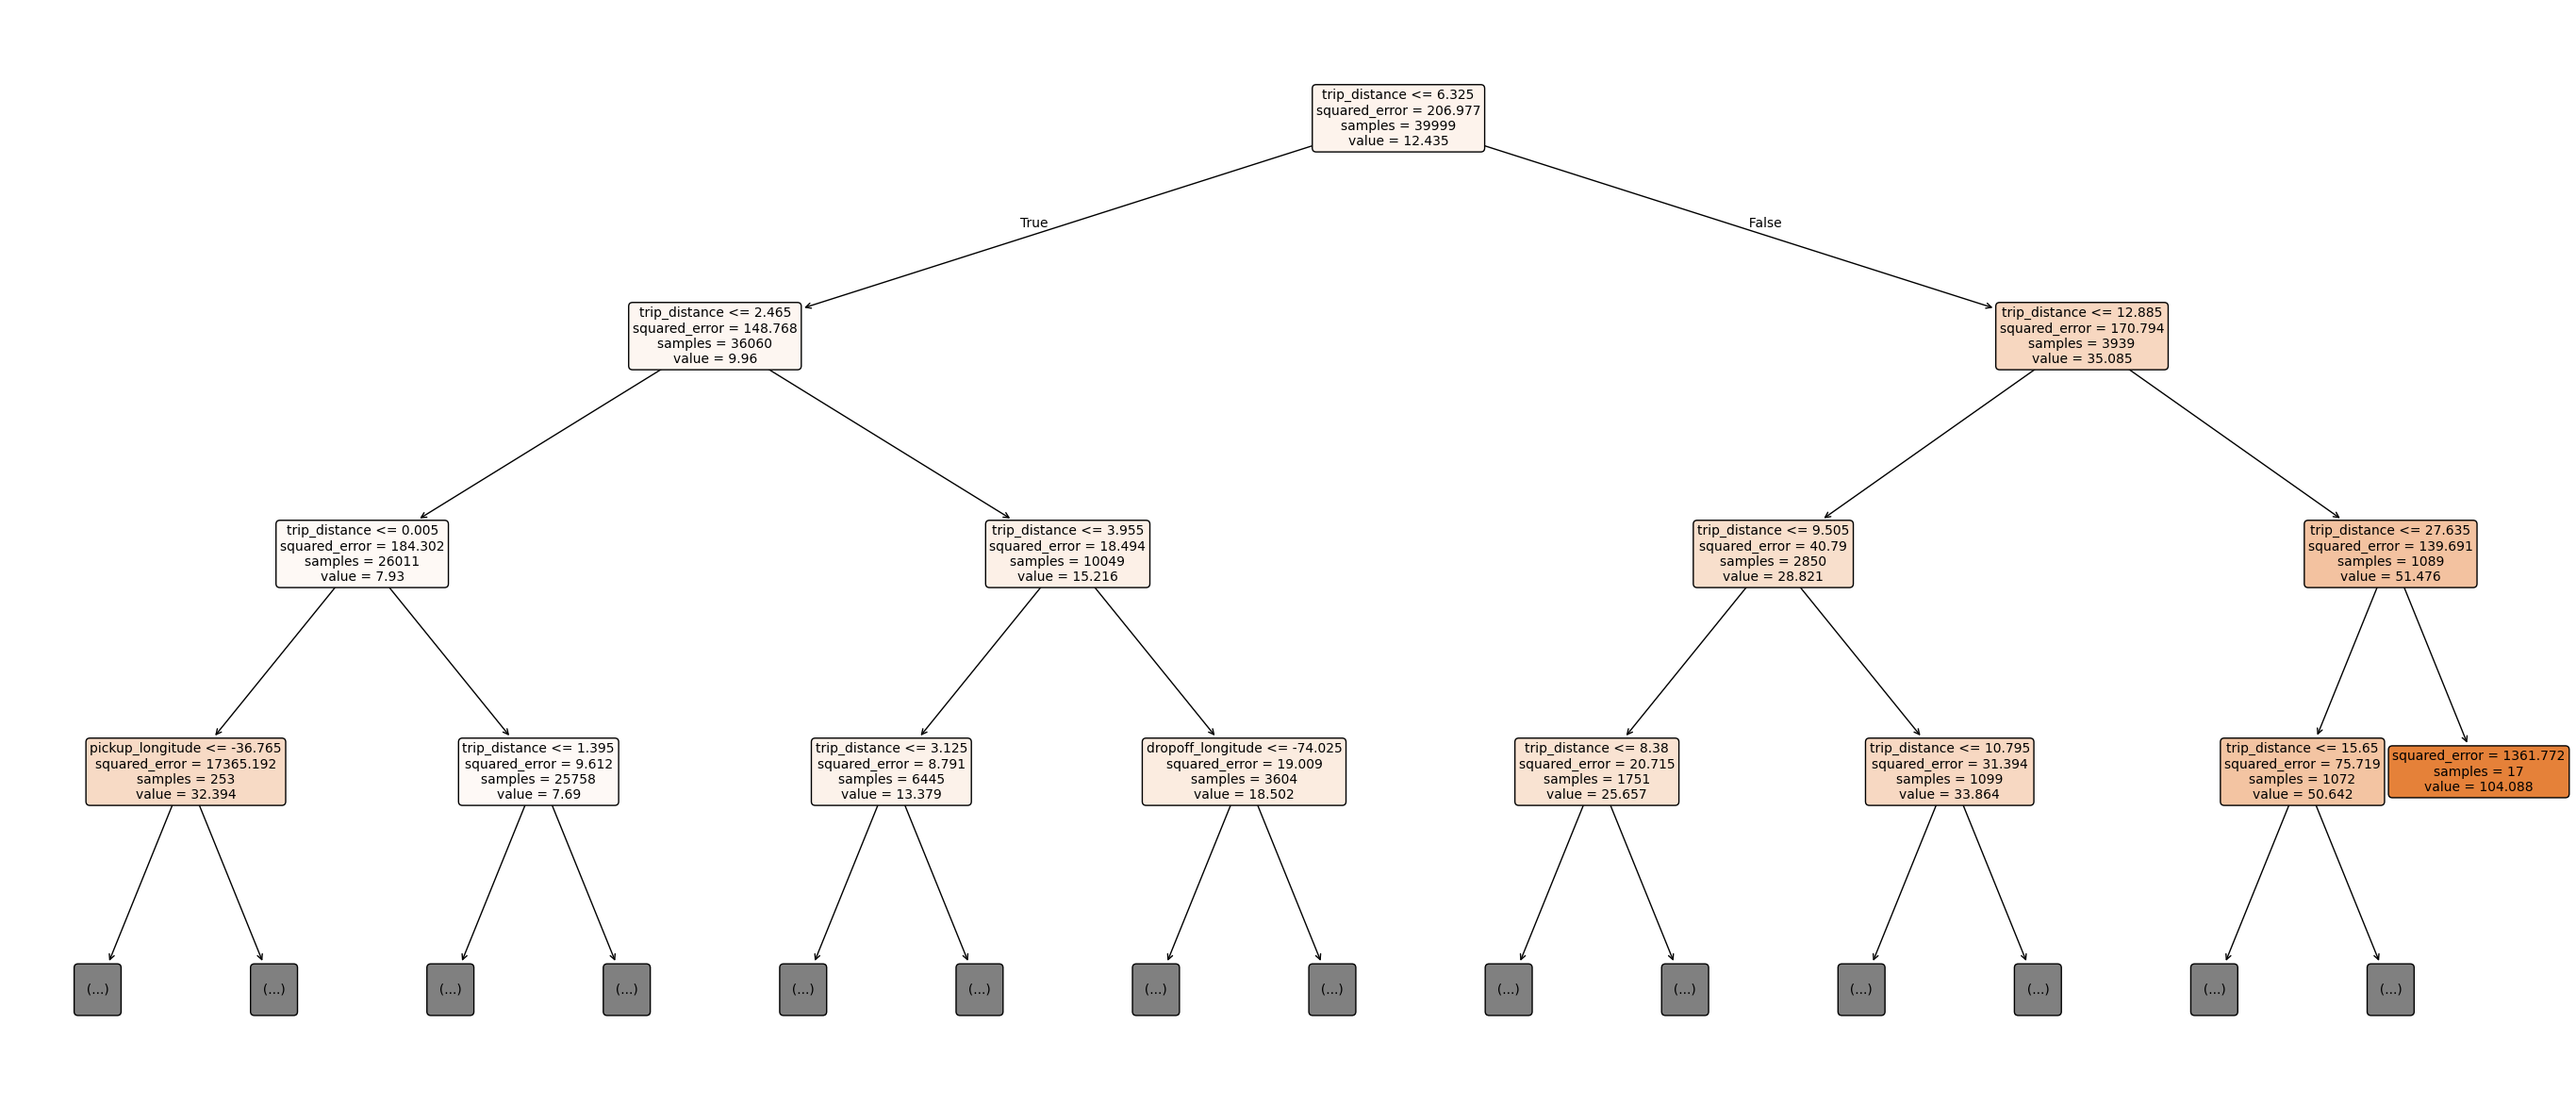

In [59]:
plt.figure(figsize=(35, 15))
plot_tree(best_tree, feature_names=vars_names, fontsize=10, filled=True,
          rounded=True, max_depth=3)
plt.show()


In [60]:
tree_rules = export_text(best_tree, feature_names=vars_names, max_depth=5)
print(tree_rules)


|--- trip_distance <= 6.33
|   |--- trip_distance <= 2.47
|   |   |--- trip_distance <= 0.00
|   |   |   |--- pickup_longitude <= -36.77
|   |   |   |   |--- pickup_longitude <= -74.03
|   |   |   |   |   |--- value: [61.29]
|   |   |   |   |--- pickup_longitude >  -74.03
|   |   |   |   |   |--- pickup_longitude <= -73.81
|   |   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |   |--- pickup_longitude >  -73.81
|   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- pickup_longitude >  -36.77
|   |   |   |   |--- passenger_count <= 1.50
|   |   |   |   |   |--- value: [86.65]
|   |   |   |   |--- passenger_count >  1.50
|   |   |   |   |   |--- value: [65.99]
|   |   |--- trip_distance >  0.00
|   |   |   |--- trip_distance <= 1.39
|   |   |   |   |--- trip_distance <= 0.89
|   |   |   |   |   |--- dropoff_latitude <= 40.82
|   |   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |   |--- dropoff_latitude >  40.82
|   |   |   |   |  